# 1. Training, Evaluasi, & Kuantisasi INT8 MobileNetV2 (100% NPU Arm Ethos-U55)

Notebook ini mengimplementasikan pipeline lengkap sesuai dokumen [training&val.md](../docs/training&val.md) dan [konsep_sistem.md](../docs/konsep_sistem.md):
1. **Pemetaan Kelas Eksplisit:**
   - **`Class 0`**: **Betina (`hen`)** $\rightarrow$ Servo `0°`
   - **`Class 1`**: **Jantan (`cock`)** $\rightarrow$ Servo `180°`
2. **Arsitektur Ultra-Ringan & 100% Kompatibel NPU:**
   - Menggunakan `MobileNetV2(alpha=0.35, input_shape=(160, 160, 3))`.
   - Tanpa layer *preprocessing* di dalam grafik model (*zero CPU-fallback ops*).
   - Dikunci ke *static input shape* `[1, 160, 160, 3]` saat ekspor TFLite agar **100% operator dieksekusi di NPU Arm Ethos-U55**.
3. **Evaluasi Lengkap:**
   - Grafik *Accuracy* & *Loss* (*Training* vs *Validation*).
   - *Confusion Matrix* & *Classification Report* pada model Float32 dan model `model_int8.tflite`.

## Langkah 0: Instalasi & Import Library
Jalankan sel di bawah ini jika ada library yang belum terinstal di environment Anda.

In [1]:
# Uncomment baris di bawah ini jika library belum terinstal
# !pip install -q tensorflow scikit-learn matplotlib seaborn pillow ethos-u-vela

In [2]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow Version : {tf.__version__}")
print(f"GPU Tersedia       : {tf.config.list_physical_devices('GPU')}")

# Set seed untuk reprodusibilitas
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

2026-10-06 15:01:25.081202: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-06 15:01:25.129285: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-06 15:01:25.401568: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-06 15:01:25.401600: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-06 15:01:25.446186: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

TensorFlow Version : 2.15.1
GPU Tersedia       : []


## Langkah 1: Konfigurasi Parameter & Pemetaan Folder Dataset

Kita mendukung dua sumber folder dataset yang ada di repositori:
1. `../data/Sexing-Chicken-2` (Memiliki pembagian folder `train/`, `valid/`, dan `test/`).
2. `../data/dateset` (Memiliki folder `hen/` dan `cock/` secara langsung, yang otomatis dibagi menjadi 80% Train dan 20% Validation).

> **Penting:** Parameter `CLASS_NAMES = ['hen', 'cock']` dikunci secara eksplisit agar:
> - Indeks `0` = `hen` (**Betina**)
> - Indeks `1` = `cock` (**Jantan**)

In [3]:
# Pilih path dataset utama:
# Opsi 1: "../data/Sexing-Chicken-2" (sudah terbagi train/valid/test)
# Opsi 2: "../data/dateset" (folder langsung hen/ dan cock/)
DATASET_DIR = pathlib.Path("../data/Sexing-Chicken-2")
if not DATASET_DIR.exists():
    DATASET_DIR = pathlib.Path("../data/dateset")

MODEL_OUTPUT_DIR = pathlib.Path("../model")
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi Model NPU-Friendly (MobileNetV2 0.35 - 160x160)
IMG_SIZE = 160
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
ALPHA = 0.35
BATCH_SIZE = 32

# Urutan kelas WAJIB: index 0 = 'hen' (Betina), index 1 = 'cock' (Jantan)
CLASS_NAMES = ["hen", "cock"]
CLASS_LABELS_ID = {0: "Class 0: Betina (hen)", 1: "Class 1: Jantan (cock)"}

# Epochs untuk Fase 1 (Head Training) & Fase 2 (Fine-Tuning)
EPOCHS_PHASE_1 = 10
EPOCHS_PHASE_2 = 15

print(f"Menggunakan Dataset : {DATASET_DIR.resolve()}")
print(f"Output Direktori    : {MODEL_OUTPUT_DIR.resolve()}")
print(f"Pemetaan Kelas      : 0 -> {CLASS_NAMES[0]} (Betina), 1 -> {CLASS_NAMES[1]} (Jantan)")

Menggunakan Dataset : /home/nexus_is/PP2/data/Sexing-Chicken-2
Output Direktori    : /home/nexus_is/PP2/model
Pemetaan Kelas      : 0 -> hen (Betina), 1 -> cock (Jantan)


In [4]:
# Memuat Dataset dengan mengunci urutan class_names=['hen', 'cock']
has_split_folders = (DATASET_DIR / "train").exists() and (DATASET_DIR / "valid").exists()

if has_split_folders:
    print("Mendeteksi struktur folder train / valid / test...")
    raw_train_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR / "train",
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED,
    )
    raw_val_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR / "valid",
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    if (DATASET_DIR / "test").exists():
        raw_test_ds = tf.keras.utils.image_dataset_from_directory(
            DATASET_DIR / "test",
            class_names=CLASS_NAMES,
            label_mode="int",
            image_size=(IMG_SIZE, IMG_SIZE),
            batch_size=BATCH_SIZE,
            shuffle=False,
        )
    else:
        raw_test_ds = raw_val_ds
else:
    print("Mendeteksi folder tunggal (hen & cock), membagi 80% Train & 20% Validation...")
    raw_train_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        class_names=CLASS_NAMES,
        label_mode="int",
        validation_split=0.2,
        subset="training",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED,
    )
    raw_val_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        class_names=CLASS_NAMES,
        label_mode="int",
        validation_split=0.2,
        subset="validation",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=False,
        seed=SEED,
    )
    raw_test_ds = raw_val_ds

print("Urutan class_names terverifikasi:", raw_train_ds.class_names)

Mendeteksi struktur folder train / valid / test...
Found 3996 files belonging to 2 classes.
Found 381 files belonging to 2 classes.
Found 191 files belonging to 2 classes.
Urutan class_names terverifikasi: ['hen', 'cock']


## Langkah 2: Preprocessing & Augmentasi di Luar Grafik Model (`tf.data`)

Agar model yang diekspor ke TFLite dapat dikompilasi **100% di NPU Ethos-U55**, kita **tidak** meletakkan layer `Rescaling` atau `RandomFlip` di dalam objek `tf.keras.Model`. Sebaliknya:
- Piksel gambar `[0, 255]` dinormalisasi ke rentang `[-1.0, 1.0]` (standar `MobileNetV2`: `(x / 127.5) - 1.0`) langsung di dalam pipeline `tf.data`.
- Saat kuantisasi `INT8`, *input scale* dan *zero-point* pada tensor input pertama akan otomatis menyerap skala tersebut di NPU!

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

# Fungsi augmentasi ringan di tf.data (hanya untuk data training)
def augment_and_preprocess(images, labels):
    images = tf.cast(images, tf.float32)
    images = tf.image.random_flip_left_right(images)
    images = tf.image.random_brightness(images, max_delta=0.15)
    images = tf.image.random_contrast(images, lower=0.85, upper=1.15)
    images = tf.clip_by_value(images, 0.0, 255.0)
    # Normalisasi standar MobileNetV2: [-1.0, 1.0]
    images = (images / 127.5) - 1.0
    return images, labels

# Fungsi preprocessing standar (untuk validation, test, dan kalibrasi INT8)
def preprocess_only(images, labels):
    images = tf.cast(images, tf.float32)
    images = (images / 127.5) - 1.0
    return images, labels

train_ds = raw_train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = raw_val_ds.map(preprocess_only, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = raw_test_ds.map(preprocess_only, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

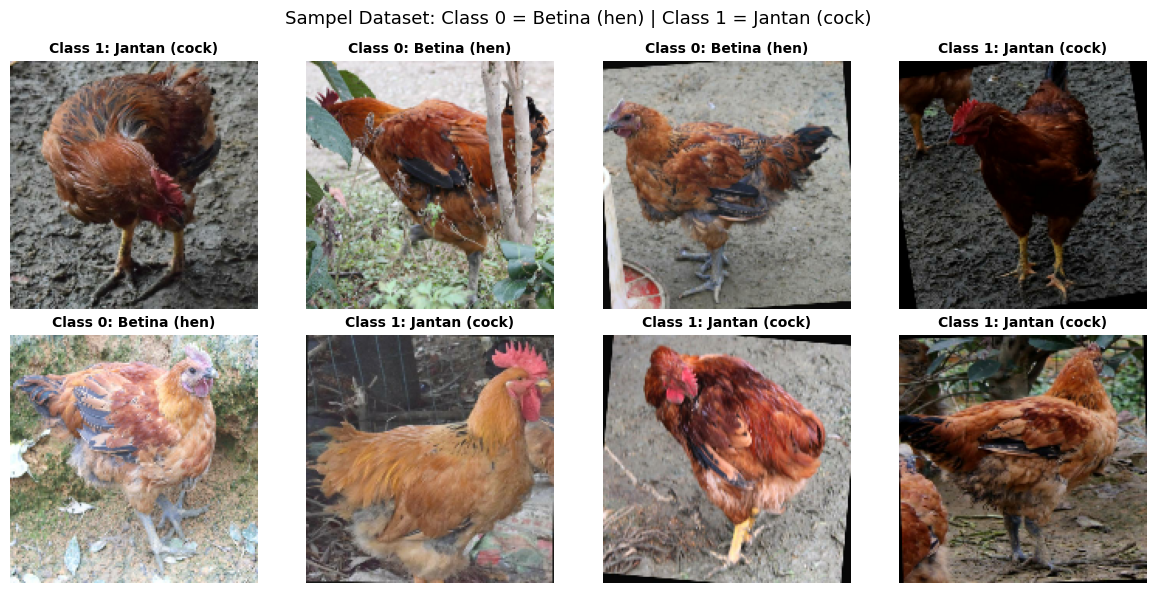

In [6]:
# Visualisasi 8 sampel gambar dari dataset training
plt.figure(figsize=(12, 6))
for images, labels in raw_train_ds.take(1):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        lbl = int(labels[i].numpy())
        plt.title(CLASS_LABELS_ID[lbl], fontsize=10, fontweight="bold")
        plt.axis("off")
plt.suptitle("Sampel Dataset: Class 0 = Betina (hen) | Class 1 = Jantan (cock)", fontsize=13)
plt.tight_layout()
plt.show()

## Langkah 3: Membangun Arsitektur MobileNetV2 Ringan (`alpha=0.35`)

Semua layer di bawah ini (`Conv2D`, `DepthwiseConv2D`, `Add`, `ReLU6`, `GlobalAveragePooling2D`, `Dense`, `Softmax`) didukung **100% secara native** oleh NPU **Arm Ethos-U55**.

In [7]:
def build_npu_mobilenetv2(input_shape=(160, 160, 3), alpha=0.35, num_classes=2):
    inputs = tf.keras.Input(shape=input_shape, name="input_image")

    # Base model MobileNetV2 ringan dengan bobot ImageNet
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        alpha=alpha,
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False  # Dibekukan pada Fase 1

    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = tf.keras.layers.Dropout(0.2, name="dropout")(x)
    # Output 2 kelas [prob_betina_0, prob_jantan_1] untuk kompatibilitas penuh dengan SenseCraft / SSCMA
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="class_probs")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=f"MobileNetV2_{alpha}_NPU")
    return model, base_model

model, base_model = build_npu_mobilenetv2(IMG_SHAPE, alpha=ALPHA, num_classes=len(CLASS_NAMES))
model.summary()

2019640/2019640 [==============================] - 2s 1us/step
Model: "MobileNetV2_0.35_NPU"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 160, 160, 3)]     0         
                                                                 
 mobilenetv2_0.35_160 (Func  (None, 5, 5, 1280)        410208    
 tional)                                                         
                                                                 
 global_avg_pool (GlobalAve  (None, 1280)              0         
 ragePooling2D)                                                  
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 class_probs (Dense)         (None, 2)                 2562      
                                                 

## Langkah 4: Training Model (2 Fase: Head Training & Fine-Tuning)

1. **Fase 1 (Feature Extraction):** Melatih *classification head* (`Dense`) dengan *base model* dibekukan.
2. **Fase 2 (Fine-Tuning):** Membuka 30 layer terakhir `MobileNetV2` dengan *learning rate* kecil (`1e-4`) agar akurasi meningkat tajam pada fitur ayam jantan & betina.

In [8]:
# --- FASE 1: Training Classification Head ---
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print("=== Memulai Training Fase 1 (Feature Extraction) ===")
history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE_1,
)

=== Memulai Training Fase 1 (Feature Extraction) ===
Epoch 1/10
125/125 [==============================] - 14s 97ms/step - loss: 0.5291 - accuracy: 0.7630 - val_loss: 0.4359 - val_accuracy: 0.8451
Epoch 2/10
125/125 [==============================] - 12s 92ms/step - loss: 0.4348 - accuracy: 0.8291 - val_loss: 0.4278 - val_accuracy: 0.8425
Epoch 3/10
125/125 [==============================] - 12s 94ms/step - loss: 0.4033 - accuracy: 0.8358 - val_loss: 0.4638 - val_accuracy: 0.8346
Epoch 4/10
125/125 [==============================] - 12s 93ms/step - loss: 0.3877 - accuracy: 0.8436 - val_loss: 0.4378 - val_accuracy: 0.8478
Epoch 5/10
125/125 [==============================] - 12s 93ms/step - loss: 0.3807 - accuracy: 0.8493 - val_loss: 0.4506 - val_accuracy: 0.8399
Epoch 6/10
125/125 [==============================] - 12s 96ms/step - loss: 0.3665 - accuracy: 0.8539 - val_loss: 0.4358 - val_accuracy: 0.8425
Epoch 7/10
125/125 [==============================] - 13s 102ms/step - loss: 0.3611

In [9]:
# --- FASE 2: Fine-Tuning ---
base_model.trainable = True

# Bekukan semua layer awal, hanya buka 30 layer terakhir
fine_tune_at = max(0, len(base_model.layers) - 30)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Penting: Jaga layer BatchNormalization tetap frozen agar statistik moving mean/variance stabil
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

total_epochs = EPOCHS_PHASE_1 + EPOCHS_PHASE_2
print("=== Memulai Training Fase 2 (Fine-Tuning) ===")
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=len(history_phase1.history["accuracy"]),
    callbacks=callbacks,
)

# Simpan model Keras Float32 terbaik
keras_model_path = MODEL_OUTPUT_DIR / "mobilenetv2_sexing_float32.keras"
model.save(keras_model_path)
print(f"Model Keras Float32 disimpan di: {keras_model_path}")

=== Memulai Training Fase 2 (Fine-Tuning) ===
Epoch 11/25
125/125 [==============================] - 16s 114ms/step - loss: 0.3580 - accuracy: 0.8546 - val_loss: 0.4769 - val_accuracy: 0.8373 - lr: 1.0000e-04
Epoch 12/25
125/125 [==============================] - 14s 107ms/step - loss: 0.3114 - accuracy: 0.8729 - val_loss: 0.4873 - val_accuracy: 0.8268 - lr: 1.0000e-04
Epoch 13/25
125/125 [==============================] - ETA: 0s - loss: 0.2761 - accuracy: 0.8859
Epoch 13: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
125/125 [==============================] - 14s 107ms/step - loss: 0.2761 - accuracy: 0.8859 - val_loss: 0.5342 - val_accuracy: 0.8399 - lr: 1.0000e-04
Epoch 14/25
125/125 [==============================] - 13s 105ms/step - loss: 0.2334 - accuracy: 0.9004 - val_loss: 0.5354 - val_accuracy: 0.8241 - lr: 5.0000e-05
Epoch 15/25
125/125 [==============================] - ETA: 0s - loss: 0.2304 - accuracy: 0.8999
Epoch 15: ReduceLROnPlateau reducing learni

## Langkah 5: Evaluasi Model (Kurva Training, Confusion Matrix, & Classification Report)

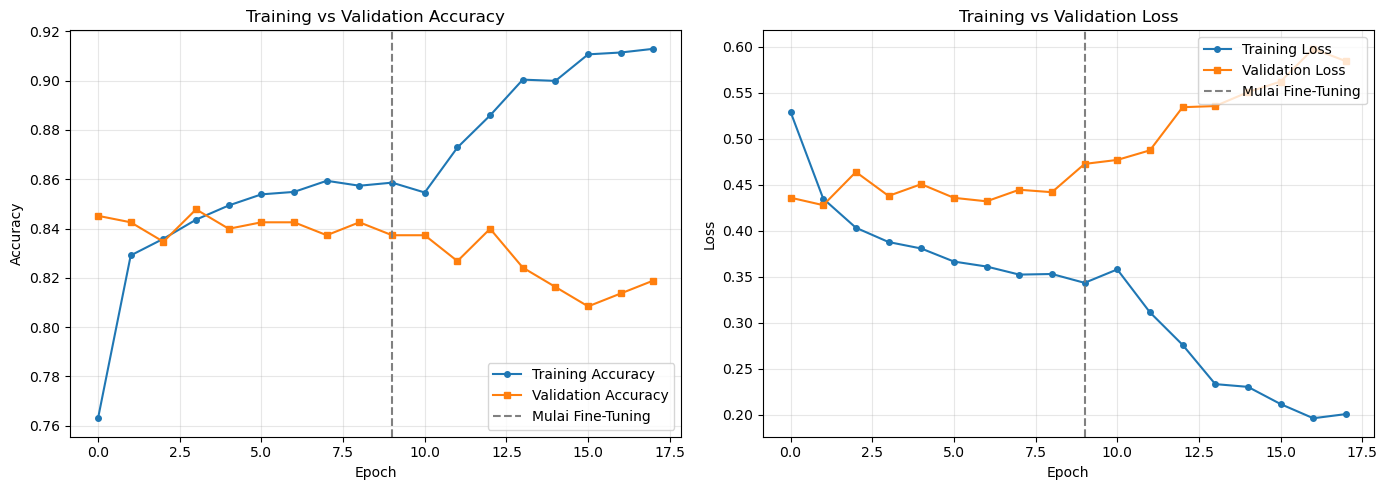

In [10]:
# Menggabungkan riwayat training Fase 1 dan Fase 2
acc = history_phase1.history["accuracy"] + history_phase2.history["accuracy"]
val_acc = history_phase1.history["val_accuracy"] + history_phase2.history["val_accuracy"]
loss = history_phase1.history["loss"] + history_phase2.history["loss"]
val_loss = history_phase1.history["val_loss"] + history_phase2.history["val_loss"]

phase1_end = len(history_phase1.history["accuracy"]) - 1

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy", marker="o", markersize=4)
plt.plot(val_acc, label="Validation Accuracy", marker="s", markersize=4)
plt.axvline(x=phase1_end, color="gray", linestyle="--", label="Mulai Fine-Tuning")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss", marker="o", markersize=4)
plt.plot(val_loss, label="Validation Loss", marker="s", markersize=4)
plt.axvline(x=phase1_end, color="gray", linestyle="--", label="Mulai Fine-Tuning")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== CLASSIFICATION REPORT (MODEL FLOAT32) ===
                        precision    recall  f1-score   support

 Class 0: Betina (hen)     0.8085    0.8539    0.8306        89
Class 1: Jantan (cock)     0.8660    0.8235    0.8442       102

              accuracy                         0.8377       191
             macro avg     0.8372    0.8387    0.8374       191
          weighted avg     0.8392    0.8377    0.8379       191



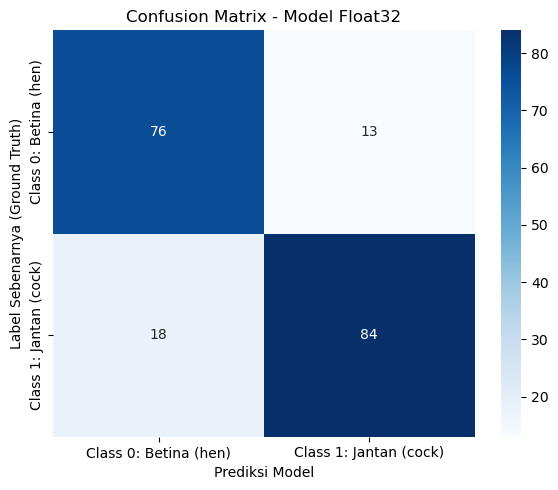

In [11]:
# Evaluasi pada Test / Validation Dataset (Model Float32)
y_true = []
y_pred_float = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred_float.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred_float = np.array(y_pred_float)

target_names = ["Class 0: Betina (hen)", "Class 1: Jantan (cock)"]
print("=== CLASSIFICATION REPORT (MODEL FLOAT32) ===")
print(classification_report(y_true, y_pred_float, target_names=target_names, digits=4))

cm_float = confusion_matrix(y_true, y_pred_float)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_float,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title("Confusion Matrix - Model Float32")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya (Ground Truth)")
plt.tight_layout()
plt.show()

## Langkah 6: Kuantisasi Penuh ke `model_int8.tflite` (100% NPU Compatible)

### Kunci Kompilasi 100% NPU (Zero CPU Operators):
1. Kita membungkus `model` dengan `@tf.function` menggunakan `tf.TensorSpec(shape=[1, IMG_SIZE, IMG_SIZE, 3], dtype=tf.float32)` agar dimensi batch statis (`1`). Hal ini mencegah TFLite menambahkan operator dinamis `SHAPE`, `STRIDED_SLICE`, dan `PACK` yang tidak didukung NPU.
2. Menggunakan `OpsSet.TFLITE_BUILTINS_INT8` dengan input dan output bertipe `tf.int8`.

In [12]:
# 1. Kunci dimensi input menjadi statis [1, 160, 160, 3] agar 100% NPU di Arm Vela
@tf.function(input_signature=[tf.TensorSpec(shape=[1, IMG_SIZE, IMG_SIZE, 3], dtype=tf.float32)])
def static_inference_fn(x):
    return model(x, training=False)

concrete_func = static_inference_fn.get_concrete_function()

# 2. Generator Representative Dataset untuk kalibrasi aktivasi INT8 (150 sampel gambar)
def representative_data_gen():
    count = 0
    for images, _ in raw_train_ds:
        images = tf.cast(images, tf.float32)
        images = (images / 127.5) - 1.0
        for i in range(images.shape[0]):
            yield [tf.expand_dims(images[i], axis=0)]
            count += 1
            if count >= 150:
                return

# 3. Konversi ke Full Integer Quantization (INT8)
converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func], model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8_bytes = converter.convert()

# 4. Simpan model_int8.tflite dan labels.txt
tflite_model_path = MODEL_OUTPUT_DIR / "model_int8.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_int8_bytes)

labels_path = MODEL_OUTPUT_DIR / "labels.txt"
with open(labels_path, "w") as f:
    f.write("0 Betina (hen)\n1 Jantan (cock)\n")

size_kb = os.path.getsize(tflite_model_path) / 1024
print(f"Berhasil membuat : {tflite_model_path.resolve()}")
print(f"Ukuran Model INT8: {size_kb:.2f} KB")

INFO:tensorflow:Assets written to: /tmp/tmpcb_2erpa/assets


INFO:tensorflow:Assets written to: /tmp/tmpcb_2erpa/assets
2026-10-06 15:05:53.792949: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-10-06 15:05:53.793305: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
2026-10-06 15:05:53.796389: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpcb_2erpa
2026-10-06 15:05:53.816276: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-10-06 15:05:53.816322: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /tmp/tmpcb_2erpa
2026-10-06 15:05:53.856535: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-10-06 15:05:53.867482: I tensorflow/cc/saved_model/loader.cc:233] Restoring SavedModel bundle.
2026-10-06 15:05:54.258816: I tensorflow/cc/saved_model/loader.cc:217] Running initializatio

Berhasil membuat : /home/nexus_is/PP2/model/model_int8.tflite
Ukuran Model INT8: 612.64 KB


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
2026-10-06 15:05:58.309973: I tensorflow/compiler/mlir/lite/flatbuffer_export.cc:2989] Estimated count of arithmetic ops: 60.697 M  ops, equivalently 30.349 M  MACs


## Langkah 7: Evaluasi Akurasi Model `model_int8.tflite`

Kita menguji langsung file `model_int8.tflite` pada seluruh dataset *Test/Validation* untuk memastikan akurasi setelah kuantisasi ke `INT8` tetap tinggi.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Input Tensor  : shape=[  1 160 160   3], dtype=<class 'numpy.int8'>, scale=0.007843, zero_point=-1
Output Tensor : shape=[1 2], dtype=<class 'numpy.int8'>, scale=0.003906, zero_point=-128

=== PERBANDINGAN AKURASI FLOAT32 vs INT8 ===
Akurasi Model Float32 : 83.77%
Akurasi Model INT8    : 84.82% (Selisih: +1.05%)

=== CLASSIFICATION REPORT (MODEL_INT8.TFLITE) ===
                        precision    recall  f1-score   support

 Class 0: Betina (hen)     0.8125    0.8764    0.8432        89
Class 1: Jantan (cock)     0.8842    0.8235    0.8528       102

              accuracy                         0.8482       191
             macro avg     0.8484    0.8500    0.8480       191
          weighted avg     0.8508    0.8482    0.8483       191



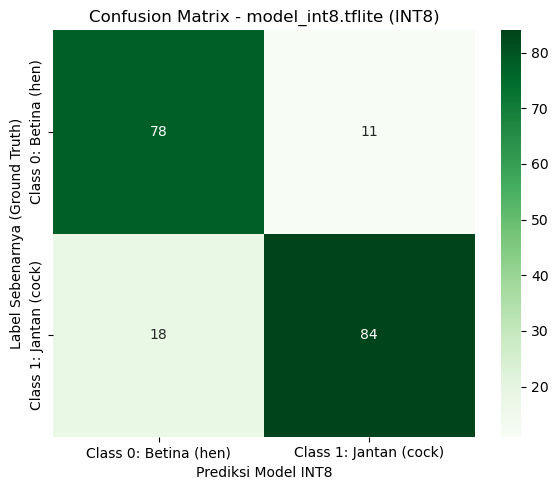

In [13]:
interpreter = tf.lite.Interpreter(model_path=str(tflite_model_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

in_scale, in_zero_point = input_details["quantization"]
out_scale, out_zero_point = output_details["quantization"]

print(f"Input Tensor  : shape={input_details['shape']}, dtype={input_details['dtype']}, scale={in_scale:.6f}, zero_point={in_zero_point}")
print(f"Output Tensor : shape={output_details['shape']}, dtype={output_details['dtype']}, scale={out_scale:.6f}, zero_point={out_zero_point}")

y_pred_int8 = []
for images, _ in test_ds:
    for i in range(images.shape[0]):
        img_float = images[i : i + 1].numpy()
        # Kuantisasi float [-1, 1] ke int8 [-128, 127]
        img_int8 = np.clip(np.round(img_float / in_scale + in_zero_point), -128, 127).astype(np.int8)
        interpreter.set_tensor(input_details["index"], img_int8)
        interpreter.invoke()
        out_int8 = interpreter.get_tensor(output_details["index"])[0]
        y_pred_int8.append(int(np.argmax(out_int8)))

y_pred_int8 = np.array(y_pred_int8)

acc_float = np.mean(y_pred_float == y_true) * 100
acc_int8 = np.mean(y_pred_int8 == y_true) * 100

print("\n=== PERBANDINGAN AKURASI FLOAT32 vs INT8 ===")
print(f"Akurasi Model Float32 : {acc_float:.2f}%")
print(f"Akurasi Model INT8    : {acc_int8:.2f}% (Selisih: {acc_int8 - acc_float:+.2f}%)")

print("\n=== CLASSIFICATION REPORT (MODEL_INT8.TFLITE) ===")
print(classification_report(y_true, y_pred_int8, target_names=target_names, digits=4))

cm_int8 = confusion_matrix(y_true, y_pred_int8)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_int8,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title("Confusion Matrix - model_int8.tflite (INT8)")
plt.xlabel("Prediksi Model INT8")
plt.ylabel("Label Sebenarnya (Ground Truth)")
plt.tight_layout()
plt.show()

## Langkah 8: Kompilasi dengan Arm Vela Compiler & Verifikasi 100% NPU

Sel di bawah ini menjalankan **Arm Vela Compiler** untuk mengompilasi `model_int8.tflite` menjadi `model_int8_vela.tflite` (khusus NPU **Arm Ethos-U55** pada Grove Vision AI V2) dan menampilkan persentase operator yang berjalan di NPU.

In [14]:
import subprocess
import shutil

if shutil.which("vela") is not None:
    cmd = [
        "vela",
        str(tflite_model_path),
        "--accelerator-config", "ethos-u55-64",
        "--optimise", "Performance",
        "--output-dir", str(MODEL_OUTPUT_DIR),
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
else:
    print("Arm Vela belum terinstal di environment ini.")
    print("Jalankan perintah berikut di terminal/notebook untuk menginstal dan mengompilasi:")
    print("  pip install ethos-u-vela")
    print(f"  vela {tflite_model_path} --accelerator-config ethos-u55-64 --optimise Performance --output-dir {MODEL_OUTPUT_DIR}")

Arm Vela belum terinstal di environment ini.
Jalankan perintah berikut di terminal/notebook untuk menginstal dan mengompilasi:
  pip install ethos-u-vela
  vela ../model/model_int8.tflite --accelerator-config ethos-u55-64 --optimise Performance --output-dir ../model
